In [10]:
import pandas as pd
df = pd.read_parquet("clean_native_lang.parquet")
print(df.shape)   # should be (223288, 97)

(223288, 97)


In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

In [12]:
df = pd.read_parquet("clean_native_lang.parquet")
q_cols = [c for c in df.columns if c.startswith("q")]

X = df[q_cols]           # 95 right/wrong answers
y = df["native_lang"]    # label: one of 10 languages
print(X.shape, y.nunique(), "languages")

(223288, 95) 10 languages


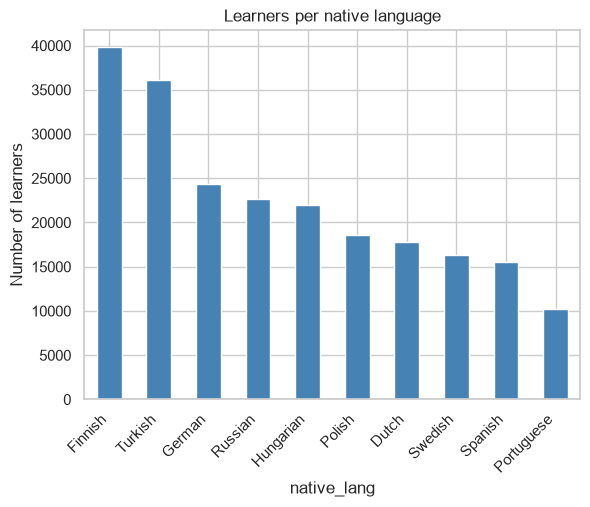

In [13]:
y.value_counts().plot.bar(color="steelblue")
plt.ylabel("Number of learners"); plt.title("Learners per native language")
plt.xticks(rotation=45, ha="right"); plt.show()

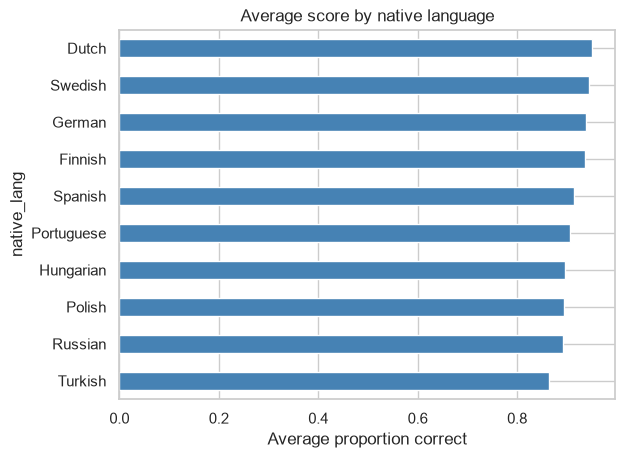

In [14]:
score = X.mean(axis=1)   # equals each person's overall score
score.groupby(y).mean().sort_values().plot.barh(color="steelblue")
plt.xlabel("Average proportion correct"); plt.title("Average score by native language"); plt.show()

In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

X_tune, _, y_tune, _ = train_test_split(
    X_train, y_train, train_size=50_000, stratify=y_train, random_state=RANDOM_STATE)

print("train:", X_train.shape, "| test:", X_test.shape, "| tuning sample:", X_tune.shape)

train: (178630, 95) | test: (44658, 95) | tuning sample: (50000, 95)


In [16]:
baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
pred = baseline.predict(X_test)
print("Baseline accuracy:", round(accuracy_score(y_test, pred), 3))
print("Baseline macro F1:", round(f1_score(y_test, pred, average="macro"), 3))

Baseline accuracy: 0.178
Baseline macro F1: 0.03


In [17]:
import time
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.base import clone

def tune(name, model, grid):
    start = time.time()
    search = GridSearchCV(model, grid, scoring="f1_macro", cv=3, n_jobs=-1)
    search.fit(X_tune, y_tune)
    print(f"{name}: best {search.best_params_} | CV macro F1 = {search.best_score_:.3f} | {time.time()-start:.0f}s")
    return search

searches = {}

In [18]:
searches["Logistic regression"] = tune("Logistic regression",
    LogisticRegression(max_iter=2000, class_weight="balanced"),
    {"C": [0.01, 0.1, 1, 10]})

Logistic regression: best {'C': 0.1} | CV macro F1 = 0.374 | 12s


In [19]:
searches["Random forest"] = tune("Random forest",
    RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=RANDOM_STATE),
    {"max_depth": [None, 20], "min_samples_leaf": [1, 5], "max_features": ["sqrt", 0.3]})

/Users/shreyarastogi/Desktop/CS363M/Final_ML_Project/.venv/lib/python3.14/site-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Random forest: best {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 5} | CV macro F1 = 0.355 | 33s


In [20]:
searches["Gradient boosting"] = tune("Gradient boosting",
    HistGradientBoostingClassifier(max_iter=300, class_weight="balanced", random_state=RANDOM_STATE),
    {"learning_rate": [0.05, 0.1], "max_depth": [None, 6]})

Gradient boosting: best {'learning_rate': 0.05, 'max_depth': None} | CV macro F1 = 0.379 | 53s


In [21]:
searches["MLP"] = tune("MLP",
    MLPClassifier(early_stopping=True, max_iter=200, random_state=RANDOM_STATE),
    {"hidden_layer_sizes": [(64,), (128,), (128, 64)], "alpha": [1e-4, 1e-3]})

MLP: best {'alpha': 0.0001, 'hidden_layer_sizes': (128,)} | CV macro F1 = 0.370 | 10s


In [22]:
final_models, rows = {}, []

pred = baseline.predict(X_test)
rows.append({"model": "Baseline (most frequent)", "accuracy": accuracy_score(y_test, pred),
             "macro F1": f1_score(y_test, pred, average="macro")})

for name, search in searches.items():
    model = clone(search.best_estimator_).fit(X_train, y_train)
    pred = model.predict(X_test)
    final_models[name] = model
    rows.append({"model": name, "accuracy": accuracy_score(y_test, pred),
                 "macro F1": f1_score(y_test, pred, average="macro")})

results = pd.DataFrame(rows).set_index("model").round(3).sort_values("macro F1", ascending=False)
results

,accuracy,macro F1
model,,
Gradient boosting,0.417,0.398
MLP,0.438,0.385
Logistic regression,0.397,0.380
Random forest,0.392,0.369
Baseline (most frequent),0.178,0.030


In [23]:
from sklearn.ensemble import VotingClassifier

vote = VotingClassifier(
    estimators=[(n, clone(searches[n].best_estimator_)) for n in ["Gradient boosting", "Logistic regression", "MLP"]],
    voting="soft", n_jobs=-1)
vote.fit(X_train, y_train)
pred = vote.predict(X_test)
print("Voting accuracy:", round(accuracy_score(y_test, pred), 3),
      "| macro F1:", round(f1_score(y_test, pred, average="macro"), 3))

Voting accuracy: 0.432 | macro F1: 0.403


In [24]:
final_models["Voting (GB + LR + MLP)"] = vote
results.loc["Voting (GB + LR + MLP)"] = [round(accuracy_score(y_test, pred), 3),
                                         round(f1_score(y_test, pred, average="macro"), 3)]
results.sort_values("macro F1", ascending=False)

,accuracy,macro F1
model,,
Voting (GB + LR + MLP),0.432,0.403
Gradient boosting,0.417,0.398
MLP,0.438,0.385
Logistic regression,0.397,0.380
Random forest,0.392,0.369
Baseline (most frequent),0.178,0.030


              precision    recall  f1-score   support

       Dutch      0.291     0.410     0.341      3559
     Finnish      0.494     0.499     0.497      7958
      German      0.400     0.386     0.393      4881
   Hungarian      0.402     0.362     0.381      4402
      Polish      0.414     0.354     0.382      3708
  Portuguese      0.315     0.267     0.289      2035
     Russian      0.447     0.426     0.436      4536
     Spanish      0.328     0.324     0.326      3111
     Swedish      0.358     0.423     0.388      3254
     Turkish      0.621     0.585     0.603      7214

    accuracy                          0.432     44658
   macro avg      0.407     0.404     0.403     44658
weighted avg      0.438     0.432     0.434     44658



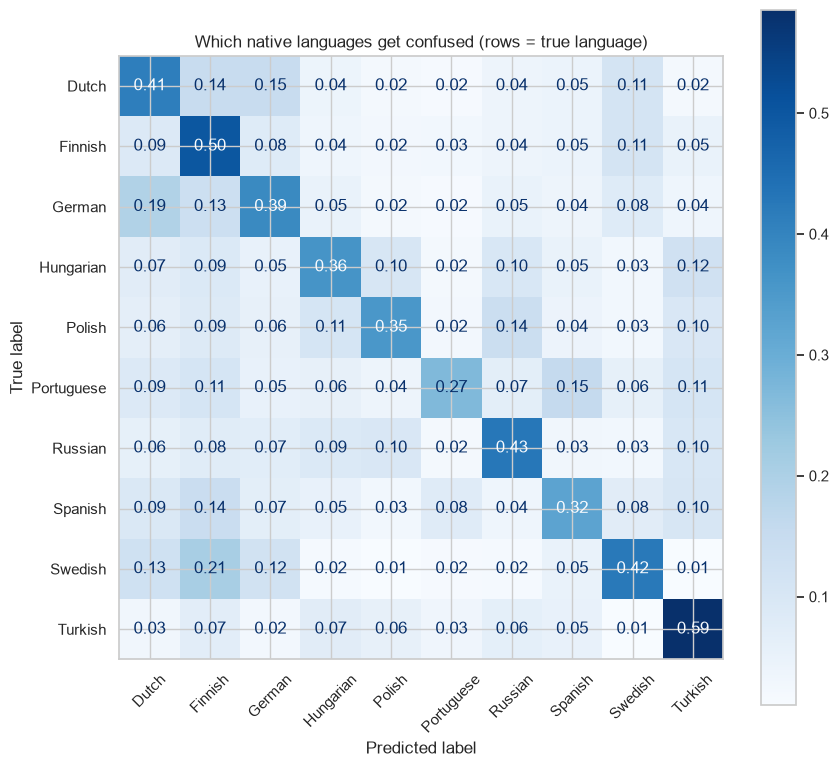

In [25]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

best = final_models["Voting (GB + LR + MLP)"]
best_pred = best.predict(X_test)

print(classification_report(y_test, best_pred, digits=3))

fig, ax = plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay.from_predictions(
    y_test, best_pred, normalize="true", values_format=".2f",
    cmap="Blues", ax=ax, xticks_rotation=45)
ax.set_title("Which native languages get confused (rows = true language)")
plt.tight_layout(); plt.show()

In [26]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import cross_val_score

class AddScore(BaseEstimator, TransformerMixin):
    """Adds each person's overall score (share of questions right) as an extra column."""
    def fit(self, X, y=None):
        return self
    def transform(self, X):
        X = X.copy()
        X["score"] = X.mean(axis=1)
        return X

class SkillAdjust(BaseEstimator, TransformerMixin):
    """Replaces each answer with (actual - expected for someone at that skill level), plus the score.
    'Expected' is learned in fit(), so inside cross-validation it only uses the training folds."""
    def __init__(self, n_bands=10):
        self.n_bands = n_bands
    def fit(self, X, y=None):
        score = X.mean(axis=1)
        self.edges_ = np.unique(np.quantile(score, np.linspace(0, 1, self.n_bands + 1)))
        band = self._band(score)
        self.expected_ = X.groupby(band).mean().reindex(range(len(self.edges_) - 1)).fillna(X.mean())
        return self
    def _band(self, score):
        return np.clip(np.searchsorted(self.edges_, score, side="right") - 1, 0, len(self.edges_) - 2)
    def transform(self, X):
        score = X.mean(axis=1)
        out = pd.DataFrame(X.values - self.expected_.values[self._band(score)], columns=X.columns, index=X.index)
        out["score"] = score
        return out

In [27]:
for name in ["Logistic regression", "Gradient boosting"]:
    base = searches[name].best_estimator_
    for label, pipe in [("plain", clone(base)),
                        ("+ score", make_pipeline(AddScore(), clone(base))),
                        ("skill-adjusted", make_pipeline(SkillAdjust(), clone(base)))]:
        s = cross_val_score(pipe, X_tune, y_tune, cv=3, scoring="f1_macro", n_jobs=-1)
        print(f"{name:20s} {label:15s} macro F1 = {s.mean():.3f}")

Logistic regression  plain           macro F1 = 0.374
Logistic regression  + score         macro F1 = 0.373
Logistic regression  skill-adjusted  macro F1 = 0.365
Gradient boosting    plain           macro F1 = 0.379
Gradient boosting    + score         macro F1 = 0.380
Gradient boosting    skill-adjusted  macro F1 = 0.378


In [29]:
## Feature experiment: adding the 37 dropped questions
"""
The original authors scored only 95 of 132 grammar decisions, dropping 37 that native speakers disagreed on. Since those items capture dialect and usage variation, they may carry native-language information. We add them and compare against the 95-question models on the same split
"""

'\nThe original authors scored only 95 of 132 grammar decisions, dropping 37 that native speakers disagreed on. Since those items capture dialect and usage variation, they may carry native-language information. We add them and compare against the 95-question models on the same split\n'

In [30]:
df132 = pd.read_parquet("clean_native_lang_132.parquet")
d_cols = [c for c in df132.columns if c.startswith("d_q")]
print(len(q_cols), "scored +", len(d_cols), "dropped questions | rows:", len(df132))
print("values in d_ columns:", sorted(pd.unique(df132[d_cols].values.ravel()), key=str)[:10])
print(df132[d_cols].isna().mean().sort_values(ascending=False).head())

X_all = df132[q_cols + d_cols]
y132 = df132["native_lang"]
Xa_train, Xa_test, ya_train, ya_test = train_test_split(
    X_all, y132, test_size=0.2, stratify=y132, random_state=RANDOM_STATE)

95 scored + 37 dropped questions | rows: 223288
values in d_ columns: [np.float64(0.0), np.float64(1.0)]
d_q4       0.0
d_q23_2    0.0
d_q28_4    0.0
d_q31_2    0.0
d_q31_3    0.0
dtype: float64


In [31]:
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline

compare = {
    "Gradient boosting (132 q)": clone(searches["Gradient boosting"].best_estimator_),
    "Logistic regression (132 q)": make_pipeline(SimpleImputer(strategy="most_frequent"),
                                                  clone(searches["Logistic regression"].best_estimator_)),
}
for name, model in compare.items():
    model.fit(Xa_train, ya_train)
    p = model.predict(Xa_test)
    final_models[name] = model
    results.loc[name] = [round(accuracy_score(ya_test, p), 3), round(f1_score(ya_test, p, average="macro"), 3)]
results.sort_values("macro F1", ascending=False)

,accuracy,macro F1
model,,
Gradient boosting (132 q),0.548,0.525
Logistic regression (132 q),0.516,0.494
Voting (GB + LR + MLP),0.432,0.403
Gradient boosting,0.417,0.398
MLP,0.438,0.385
Logistic regression,0.397,0.380
Random forest,0.392,0.369
Baseline (most frequent),0.178,0.030
